In [ ]:
import os, json, warnings, random, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

drive.mount("/content/drive")
DRIVE_DIR = Path("/content/drive/MyDrive")
INPUT_FILE = DRIVE_DIR / "model_ready_category_dataset.csv"
OUT_DIR = DRIVE_DIR / "model_5_category_specific_ensemble_revised_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATE_COL = "week_start"
CATEGORY_COL = "Product Category"
TARGET_COL = "weekly_quantity"

SEASONAL_PERIOD = 52
EPS = 1e-12

OUTER_ORIGINS = {
    "spring_2025": "2025-04-07",
    "summer_2025": "2025-07-07",
    "early_autumn_2025": "2025-09-08",
    "q4_year_end_2025": "2025-10-06",
}
FORECAST_HORIZONS = [4, 8, 12]
MAX_HORIZON = 12

INNER_CV_HORIZON = 4
INNER_CV_OFFSETS_WEEKS = [12, 8, 4]

CALIBRATION_OFFSETS_WEEKS = [36, 24, 12]
CALIBRATION_HORIZON = 12

OPTIONAL_EXOGENOUS = ["transaction_count", "active_customer_count"]
EXOG_LAGS = [12, 26, 52]

INTERVAL_LEVELS = [0.80, 0.95]

print("Input:", INPUT_FILE)
print("Output:", OUT_DIR)

Mounted at /content/drive
Input: /content/drive/MyDrive/model_ready_category_dataset.csv
Output: /content/drive/MyDrive/model_5_category_specific_ensemble_revised_outputs


In [ ]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

raw = pd.read_csv(INPUT_FILE)
raw[DATE_COL] = pd.to_datetime(raw[DATE_COL])

required = [CATEGORY_COL, DATE_COL, TARGET_COL]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

available_exog = [c for c in OPTIONAL_EXOGENOUS if c in raw.columns]
raw = raw[required + available_exog].copy().dropna(subset=required)
raw[CATEGORY_COL] = raw[CATEGORY_COL].astype(str)

if raw.duplicated([CATEGORY_COL, DATE_COL]).any():
    raise ValueError("Duplicate category-week observations detected.")

categories = sorted(raw[CATEGORY_COL].unique())
dataset_min = raw[DATE_COL].min()
dataset_max = raw[DATE_COL].max()
full_weeks = pd.date_range(dataset_min, dataset_max, freq="7D")

parts = []
for cat in categories:
    x = raw[raw[CATEGORY_COL] == cat].set_index(DATE_COL)[[TARGET_COL] + available_exog].reindex(full_weeks)
    x.index.name = DATE_COL
    x[TARGET_COL] = x[TARGET_COL].fillna(0.0).clip(lower=0)
    for c in available_exog:
        x[c] = x[c].fillna(0.0).clip(lower=0)
    x[CATEGORY_COL] = cat
    parts.append(x.reset_index())

panel = pd.concat(parts, ignore_index=True).sort_values([CATEGORY_COL, DATE_COL]).reset_index(drop=True)

print("Shape:", panel.shape)
print("Categories:", len(categories))
print("Date range:", dataset_min.date(), "to", dataset_max.date())
print("Operational variables:", available_exog if available_exog else "none")

Shape: (6200, 4)
Categories: 40
Date range: 2023-01-09 to 2025-12-22
Operational variables: ['transaction_count']


In [ ]:
scenario_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    for h in FORECAST_HORIZONS:
        dates = pd.date_range(origin, periods=h, freq="7D")
        if dates[-1] > dataset_max:
            raise ValueError(f"{label}, h={h} exceeds dataset end")
        scenario_rows.append({
            "scenario_id": f"{label}_h{h}",
            "outer_origin_label": label,
            "outer_origin": origin,
            "horizon_weeks": h,
            "test_start": dates[0],
            "test_end": dates[-1],
        })

scenarios = pd.DataFrame(scenario_rows)
display(scenarios)
scenarios.to_csv(OUT_DIR / "model_5_common_rolling_origin_scenarios.csv", index=False, encoding="utf-8-sig")

,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


In [ ]:
def mae(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return float(np.mean(np.abs(a - p)))

def rmse(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    return float(np.sqrt(np.mean((a - p) ** 2)))

def mape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    mask = np.abs(a) > EPS
    return np.nan if mask.sum() == 0 else float(np.mean(np.abs((a[mask] - p[mask]) / a[mask])) * 100)

def smape(a, p):
    a, p = np.asarray(a, float), np.asarray(p, float)
    d = np.abs(a) + np.abs(p)
    return float(np.mean(np.where(d > EPS, 2 * np.abs(a - p) / d, 0)) * 100)

def mase_scale_info(y_train, m=52):
    y = np.asarray(y_train, float)
    if len(y) <= m:
        return np.nan, "insufficient_history"
    scale = float(np.mean(np.abs(y[m:] - y[:-m])))
    if not np.isfinite(scale):
        return np.nan, "non_finite_scale"
    if scale <= EPS:
        return np.nan, "zero_seasonal_scale"
    return scale, "valid"

def evaluate(a, p, y_train, m=52):
    scale, status = mase_scale_info(y_train, m)
    return {
        "MAE": mae(a, p),
        "RMSE": rmse(a, p),
        "MAPE": mape(a, p),
        "MAPE_N": int(np.sum(np.abs(np.asarray(a, float)) > EPS)),
        "sMAPE": smape(a, p),
        "MASE": np.nan if not np.isfinite(scale) else mae(a, p) / scale,
        "MASE_scale": scale,
        "MASE_status": status,
    }

print("MASE seasonal period:", SEASONAL_PERIOD)

MASE seasonal period: 52


In [ ]:
def seasonal_naive(y, h, m=52):
    y = np.asarray(y, float)
    if len(y) < m:
        return np.repeat(np.mean(y[-min(8, len(y)):]) if len(y) else 0.0, h)
    base = y[-m:]
    return np.array([base[i % m] for i in range(h)], float)

def moving_average_recursive(y, h, w):
    hist = list(np.asarray(y, float)); out = []
    for _ in range(h):
        p = float(np.mean(hist[-min(w, len(hist)):])) if hist else 0.0
        p = max(p, 0.0); out.append(p); hist.append(p)
    return np.asarray(out)

def croston(y, h, alpha=.1, sba=False):
    y = np.asarray(y, float); nz = np.where(y > 0)[0]
    if len(nz) == 0:
        return np.zeros(h)
    z = y[nz[0]]; p = max(nz[0] + 1, 1); last = nz[0]
    for idx in nz[1:]:
        q = idx - last
        z = z + alpha * (y[idx] - z)
        p = p + alpha * (q - p)
        last = idx
    f = z / max(p, EPS)
    if sba:
        f *= (1 - alpha / 2)
    return np.repeat(max(f, 0), h)

def tsb(y, h, ad=.1, ap=.1):
    y = np.asarray(y, float)
    if len(y) == 0:
        return np.zeros(h)
    pos = y[y > 0]
    z = pos[0] if len(pos) else 0.0
    prob = 1.0 if y[0] > 0 else 0.0
    for v in y[1:]:
        occ = 1.0 if v > 0 else 0.0
        prob = prob + ap * (occ - prob)
        if occ:
            z = z + ad * (v - z)
    return np.repeat(max(prob * z, 0), h)

def adida(y, h, k=4):
    y = np.asarray(y, float); n = (len(y) // k) * k
    if n < k:
        return np.repeat(np.mean(y) if len(y) else 0.0, h)
    agg = y[-n:].reshape(-1, k).sum(axis=1)
    return np.repeat(max(float(np.mean(agg) / k), 0), h)

def imapa(y, h):
    return np.mean(np.vstack([adida(y, h, k) for k in (2, 4, 8)]), axis=0)

def ets_forecast(y, h, kind):
    y = np.asarray(y, float)
    if len(y) < 12:
        return moving_average_recursive(y, h, 4)
    try:
        if kind == "ses":
            fit = SimpleExpSmoothing(y, initialization_method="estimated").fit(optimized=True)
        elif kind == "holt":
            fit = Holt(y, damped_trend=True, initialization_method="estimated").fit(optimized=True)
        elif kind == "ets_add_seasonal":
            if len(y) < 2 * SEASONAL_PERIOD:
                return seasonal_naive(y, h, SEASONAL_PERIOD)
            fit = ExponentialSmoothing(
                y, trend=None, seasonal="add", seasonal_periods=SEASONAL_PERIOD,
                initialization_method="estimated"
            ).fit(optimized=True, use_brute=False)
        elif kind == "ets_add_trend_seasonal":
            if len(y) < 2 * SEASONAL_PERIOD:
                return seasonal_naive(y, h, SEASONAL_PERIOD)
            fit = ExponentialSmoothing(
                y, trend="add", damped_trend=True, seasonal="add",
                seasonal_periods=SEASONAL_PERIOD, initialization_method="estimated"
            ).fit(optimized=True, use_brute=False)
        else:
            raise ValueError(kind)
        return np.maximum(np.asarray(fit.forecast(h), float), 0.0)
    except Exception:
        return seasonal_naive(y, h, SEASONAL_PERIOD)

CLASSICAL = [
    {"id":"seasonal_naive_52","family":"seasonal_naive"},
    {"id":"ma_4","family":"moving_average","w":4},
    {"id":"ma_12","family":"moving_average","w":12},
    {"id":"ma_26","family":"moving_average","w":26},
    {"id":"ses","family":"ets","kind":"ses"},
    {"id":"holt_damped","family":"ets","kind":"holt"},
    {"id":"ets_add_seasonal_52","family":"ets","kind":"ets_add_seasonal"},
    {"id":"ets_add_trend_seasonal_52","family":"ets","kind":"ets_add_trend_seasonal"},
    {"id":"croston_a10","family":"croston","alpha":.10},
    {"id":"sba_a10","family":"sba","alpha":.10},
    {"id":"tsb_10_10","family":"tsb","ad":.10,"ap":.10},
    {"id":"tsb_20_10","family":"tsb","ad":.20,"ap":.10},
    {"id":"adida_4","family":"adida","k":4},
    {"id":"imapa_2_4_8","family":"imapa"},
]

ML = [
    {"id":"extra_trees_raw","family":"extra_trees","transform":"raw"},
    {"id":"extra_trees_log1p","family":"extra_trees","transform":"log1p"},
    {"id":"random_forest_raw","family":"random_forest","transform":"raw"},
    {"id":"hist_gb_raw","family":"hist_gb","transform":"raw"},
    {"id":"hist_gb_log1p","family":"hist_gb","transform":"log1p"},
    {"id":"lightgbm_l2_raw","family":"lightgbm_l2","transform":"raw"},
    {"id":"lightgbm_l2_log1p","family":"lightgbm_l2","transform":"log1p"},
    {"id":"lightgbm_poisson","family":"lightgbm_poisson","transform":"raw"},
    {"id":"lightgbm_tweedie","family":"lightgbm_tweedie","transform":"raw"},
    {"id":"xgboost_l2_raw","family":"xgboost_l2","transform":"raw"},
    {"id":"xgboost_l2_log1p","family":"xgboost_l2","transform":"log1p"},
    {"id":"xgboost_poisson","family":"xgboost_poisson","transform":"raw"},
]

EXPERTS = CLASSICAL + ML
EXPERT_MAP = {x["id"]: x for x in EXPERTS}

print("TOTAL EXPERT CANDIDATES:", len(EXPERTS))
display(pd.DataFrame(EXPERTS))

TOTAL EXPERT CANDIDATES: 26


,id,family,w,kind,alpha,ad,ap,k,transform
0,seasonal_naive_52,seasonal_naive,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ma_4,moving_average,4.0,NaN,NaN,NaN,NaN,NaN,NaN
2,ma_12,moving_average,12.0,NaN,NaN,NaN,NaN,NaN,NaN
3,ma_26,moving_average,26.0,NaN,NaN,NaN,NaN,NaN,NaN
4,ses,ets,NaN,ses,NaN,NaN,NaN,NaN,NaN
5,holt_damped,ets,NaN,holt,NaN,NaN,NaN,NaN,NaN
6,ets_add_seasonal_52,ets,NaN,ets_add_seasonal,NaN,NaN,NaN,NaN,NaN
7,ets_add_trend_seasonal_52,ets,NaN,ets_add_trend_seasonal,NaN,NaN,NaN,NaN,NaN
8,croston_a10,croston,NaN,NaN,0.1,NaN,NaN,NaN,NaN
9,sba_a10,sba,NaN,NaN,0.1,NaN,NaN,NaN,NaN


In [13]:
observed_exog = {}
for cat in categories:
    d = panel[panel[CATEGORY_COL] == cat].set_index(DATE_COL)
    observed_exog[cat] = {c: d[c].to_dict() for c in available_exog}

LAGS = [1, 2, 4, 8, 12, 26, 52]
ROLLS = [4, 8, 12, 26]

def feature_row(cat, date, history):
    y = np.asarray(history, float)
    d = pd.Timestamp(date)
    w = int(d.isocalendar().week)
    r = {
        "year": d.year, "month": d.month, "quarter": d.quarter, "week_of_year": w,
        "week_sin": np.sin(2*np.pi*w/52), "week_cos": np.cos(2*np.pi*w/52),
        "month_sin": np.sin(2*np.pi*d.month/12), "month_cos": np.cos(2*np.pi*d.month/12),
    }
    for lag in LAGS:
        r[f"lag_{lag}"] = float(y[-lag]) if len(y) >= lag else 0.0
    for k in ROLLS:
        z = y[-k:] if len(y) else np.array([0.0])
        r[f"rolling_mean_{k}"] = float(np.mean(z))
        r[f"rolling_median_{k}"] = float(np.median(z))
        r[f"rolling_std_{k}"] = float(np.std(z, ddof=1)) if len(z) > 1 else 0.0
        r[f"rolling_max_{k}"] = float(np.max(z))
        r[f"positive_ratio_{k}"] = float(np.mean(z > 0))
    for c in available_exog:
        for lag in EXOG_LAGS:
            src = d - pd.Timedelta(weeks=lag)
            r[f"{c}_lag_{lag}"] = float(observed_exog[cat][c].get(src, 0.0))
    return r

CAL = ["year","month","quarter","week_of_year","week_sin","week_cos","month_sin","month_cos"]
TARGET_FEATS = (
    [f"lag_{x}" for x in LAGS] +
    [f"{a}_{k}" for k in ROLLS for a in ["rolling_mean","rolling_median","rolling_std","rolling_max","positive_ratio"]]
)
EXOG_FEATS = [f"{c}_lag_{lag}" for c in available_exog for lag in EXOG_LAGS]
FEATURE_COLS = CAL + TARGET_FEATS + EXOG_FEATS

def supervised_for_category(history, cat):
    d = history[history[CATEGORY_COL] == cat].sort_values(DATE_COL)
    vals = d[TARGET_COL].values.astype(float)
    dates = d[DATE_COL].tolist()
    rows = []
    for i in range(SEASONAL_PERIOD, len(vals)):
        r = feature_row(cat, dates[i], vals[:i])
        r[TARGET_COL] = vals[i]
        rows.append(r)
    return pd.DataFrame(rows)

def make_ml(cfg):
    f = cfg["family"]
    if f == "extra_trees":
        return ExtraTreesRegressor(n_estimators=250,max_depth=8,min_samples_leaf=2,random_state=SEED,n_jobs=-1)
    if f == "random_forest":
        return RandomForestRegressor(n_estimators=250,max_depth=8,min_samples_leaf=2,random_state=SEED,n_jobs=-1)
    if f == "hist_gb":
        return HistGradientBoostingRegressor(max_iter=250,learning_rate=.04,max_leaf_nodes=15,l2_regularization=1.0,random_state=SEED)
    if f == "lightgbm_l2":
        return LGBMRegressor(objective="regression",n_estimators=300,learning_rate=.03,num_leaves=15,max_depth=6,min_child_samples=8,reg_lambda=1.0,random_state=SEED,verbose=-1,n_jobs=-1)
    if f == "lightgbm_poisson":
        return LGBMRegressor(objective="poisson",n_estimators=300,learning_rate=.03,num_leaves=15,max_depth=6,min_child_samples=8,reg_lambda=1.0,random_state=SEED,verbose=-1,n_jobs=-1)
    if f == "lightgbm_tweedie":
        return LGBMRegressor(objective="tweedie",tweedie_variance_power=1.3,n_estimators=300,learning_rate=.03,num_leaves=15,max_depth=6,min_child_samples=8,reg_lambda=1.0,random_state=SEED,verbose=-1,n_jobs=-1)
    if f == "xgboost_l2":
        return XGBRegressor(objective="reg:squarederror",n_estimators=300,learning_rate=.03,max_depth=4,min_child_weight=3,reg_lambda=1.0,random_state=SEED,n_jobs=-1)
    if f == "xgboost_poisson":
        return XGBRegressor(objective="count:poisson",n_estimators=300,learning_rate=.03,max_depth=4,min_child_weight=3,reg_lambda=1.0,random_state=SEED,n_jobs=-1)
    raise ValueError(f)

def fit_predict_ml(history, cat, dates, cfg, origin):
    sup = supervised_for_category(history, cat)

    y_hist = (
        history[history[CATEGORY_COL] == cat]
        .sort_values(DATE_COL)[TARGET_COL]
        .values.astype(float)
    )
    if len(sup) < 20:
        return moving_average_recursive(
            y_hist,
            len(dates),
            8
        )
    if cfg["family"] in {"lightgbm_poisson", "xgboost_poisson"}:
        y_train_check = sup[TARGET_COL].astype(float).values

        if (
            len(y_train_check) == 0
            or not np.isfinite(y_train_check).all()
            or np.sum(y_train_check) <= EPS
        ):
            return seasonal_naive(
                y_hist,
                len(dates),
                SEASONAL_PERIOD
            )
    model = make_ml(cfg)

    transform = cfg.get("transform", "raw")

    y_fit = sup[TARGET_COL].astype(float).values

    if transform == "log1p":
        y_fit = np.log1p(
            np.maximum(y_fit, 0.0)
        )

    model.fit(
        sup[FEATURE_COLS].astype(float),
        y_fit
    )
    working = y_hist.tolist()
    out = []

    for d in pd.to_datetime(dates):
        if available_exog:
            for lag in EXOG_LAGS:
                assert (
                    pd.Timestamp(d) - pd.Timedelta(weeks=lag)
                    < pd.Timestamp(origin)
                )

        row = feature_row(
            cat,
            d,
            working
        )

        X_future = (
            pd.DataFrame([row])[FEATURE_COLS]
            .astype(float)
        )

        raw_pred = float(
            model.predict(X_future)[0]
        )

        if transform == "log1p":
            p = np.expm1(raw_pred)
        else:
            p = raw_pred

        p = max(float(p), 0.0)

        out.append(p)
        working.append(p)

    return np.asarray(out)

def forecast_expert(history, cat, dates, cfg, origin):
    dates = pd.to_datetime(dates)
    y = history[history[CATEGORY_COL] == cat].sort_values(DATE_COL)[TARGET_COL].values.astype(float)
    h = len(dates)
    f = cfg["family"]

    if f == "seasonal_naive": return seasonal_naive(y, h, 52)
    if f == "moving_average": return moving_average_recursive(y, h, cfg["w"])
    if f == "ets": return ets_forecast(y, h, cfg["kind"])
    if f == "croston": return croston(y, h, cfg["alpha"], False)
    if f == "sba": return croston(y, h, cfg["alpha"], True)
    if f == "tsb": return tsb(y, h, cfg["ad"], cfg["ap"])
    if f == "adida": return adida(y, h, cfg["k"])
    if f == "imapa": return imapa(y, h)
    return fit_predict_ml(history, cat, dates, cfg, origin)

def inner_folds(origin):
    out = []
    for fold, off in enumerate(INNER_CV_OFFSETS_WEEKS, 1):
        vo = pd.Timestamp(origin) - pd.Timedelta(weeks=off)
        dates = pd.date_range(vo, periods=INNER_CV_HORIZON, freq="7D")
        assert dates[-1] < pd.Timestamp(origin)
        out.append((fold, vo, dates))
    return out

def calibration_blocks(origin):
    out = []
    for block, off in enumerate(CALIBRATION_OFFSETS_WEEKS, 1):
        co = pd.Timestamp(origin) - pd.Timedelta(weeks=off)
        dates = pd.date_range(co, periods=CALIBRATION_HORIZON, freq="7D")
        assert dates[-1] < pd.Timestamp(origin)
        out.append((block, co, dates))
    return out

In [14]:
def rank_experts(fold_df):
    agg = (
        fold_df.groupby(["expert_id","family"], as_index=False)
        .agg(
            mean_MASE=("MASE","mean"), std_MASE=("MASE","std"),
            mean_sMAPE=("sMAPE","mean"), mean_RMSE=("RMSE","mean"),
            mean_MAE=("MAE","mean"), valid_MASE_N=("MASE","count")
        )
    )
    if agg["mean_MASE"].notna().any():
        return agg.sort_values(["mean_MASE","std_MASE","mean_RMSE","mean_MAE"], na_position="last").reset_index(drop=True), "MASE"
    return agg.sort_values(["mean_sMAPE","mean_RMSE","mean_MAE"]).reset_index(drop=True), "sMAPE"

def strategy_specs(ranked):
    specs = []
    if len(ranked):
        specs.append(("single_best", [ranked.iloc[0].expert_id]))
    if len(ranked) >= 3:
        specs.append(("top3_equal", ranked.head(3).expert_id.tolist()))
        specs.append(("top3_regularized_weighted", ranked.head(3).expert_id.tolist()))

    diverse, seen = [], set()
    for _, r in ranked.iterrows():
        if r.family not in seen:
            diverse.append(r.expert_id); seen.add(r.family)
        if len(diverse) >= 4:
            break
    if len(diverse) >= 2:
        specs.append(("family_diverse_weighted", diverse))
    return specs

def strategy_weights(strategy, ids, ranked, metric):
    if strategy == "top3_equal":
        return np.repeat(1.0 / len(ids), len(ids))

    z = ranked.set_index("expert_id").loc[ids]
    col = "mean_MASE" if metric == "MASE" else "mean_sMAPE"
    e = z[col].astype(float).values
    finite = e[np.isfinite(e) & (e > EPS)]
    fallback = float(np.median(finite)) if len(finite) else 1.0
    e = np.where(np.isfinite(e) & (e > EPS), e, fallback * 10)

    inv = 1.0 / np.sqrt(np.maximum(e, EPS))
    return inv / inv.sum()

def combine_predictions(ids, weights, pred_map):
    return np.average(np.vstack([pred_map[x] for x in ids]), axis=0, weights=weights)

def finite_sample_quantile(scores, level):
    s = np.asarray(scores, float)
    s = s[np.isfinite(s)]
    if len(s) == 0:
        return np.nan
    rank = int(np.ceil((len(s) + 1) * level))
    rank = min(max(rank, 1), len(s))
    return float(np.sort(s)[rank - 1])

def choose_strategy_from_nested(nested_df):
    agg = (
        nested_df.groupby("strategy", as_index=False)
        .agg(
            cv_mean_MASE=("MASE","mean"),
            cv_std_MASE=("MASE","std"),
            cv_mean_sMAPE=("sMAPE","mean"),
            cv_mean_RMSE=("RMSE","mean"),
            cv_mean_MAE=("MAE","mean"),
            valid_MASE_N=("MASE","count"),
        )
    )
    if agg.cv_mean_MASE.notna().any():
        agg = agg.sort_values(
            ["cv_mean_MASE","cv_std_MASE","cv_mean_RMSE","cv_mean_MAE"],
            na_position="last"
        )
        criterion = "MASE"
    else:
        agg = agg.sort_values(["cv_mean_sMAPE","cv_mean_RMSE","cv_mean_MAE"])
        criterion = "sMAPE"
    return agg.reset_index(drop=True), criterion

In [15]:
all_fold_rows = []
all_nested_strategy_rows = []
selections = []

for origin_label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    print("\n" + "="*100)
    print("MODEL 5 INNER SELECTION:", origin_label, origin.date())
    print("="*100)

    for ci, cat in enumerate(categories, 1):
        fold_records = []
        fold_pred_store = {}

        for fold, vo, vdates in inner_folds(origin):
            train = panel[panel[DATE_COL] < vo].copy()
            actual = panel[(panel[CATEGORY_COL] == cat) & (panel[DATE_COL].isin(vdates))].sort_values(DATE_COL)
            hist = train[train[CATEGORY_COL] == cat].sort_values(DATE_COL)[TARGET_COL].values.astype(float)
            y = actual[TARGET_COL].values.astype(float)

            assert len(y) == INNER_CV_HORIZON
            assert train[DATE_COL].max() < vdates[0]

            for cfg in EXPERTS:
                try:
                    p = forecast_expert(train, cat, vdates, cfg, vo)
                    met = evaluate(y, p, hist, SEASONAL_PERIOD)
                    status = "ok"
                except Exception as e:
                    p = moving_average_recursive(hist, len(vdates), 8)
                    met = evaluate(y, p, hist, SEASONAL_PERIOD)
                    status = "fallback"

                fold_pred_store[(fold, cfg["id"])] = np.asarray(p, float)
                row = {
                    "outer_origin_label": origin_label, "outer_origin": origin,
                    "category": cat, "inner_fold": fold, "validation_origin": vo,
                    "expert_id": cfg["id"], "family": cfg["family"], "status": status,
                    **met
                }
                fold_records.append(row)
                all_fold_rows.append(row)

        fdf = pd.DataFrame(fold_records)

        nested_rows_cat = []
        for held_fold, held_vo, held_dates in inner_folds(origin):
            selection_folds = [f for f, _, _ in inner_folds(origin) if f != held_fold]
            rank_df = fdf[fdf.inner_fold.isin(selection_folds)].copy()
            ranked, metric = rank_experts(rank_df)

            actual = panel[(panel[CATEGORY_COL] == cat) & (panel[DATE_COL].isin(held_dates))].sort_values(DATE_COL)
            y = actual[TARGET_COL].values.astype(float)
            train = panel[panel[DATE_COL] < held_vo].copy()
            hist = train[train[CATEGORY_COL] == cat].sort_values(DATE_COL)[TARGET_COL].values.astype(float)

            for sname, ids in strategy_specs(ranked):
                w = strategy_weights(sname, ids, ranked, metric)
                pred_map = {x: fold_pred_store[(held_fold, x)] for x in ids}
                p = combine_predictions(ids, w, pred_map)
                met = evaluate(y, p, hist, SEASONAL_PERIOD)

                rec = {
                    "outer_origin_label": origin_label, "outer_origin": origin,
                    "category": cat, "held_out_fold": held_fold,
                    "validation_origin": held_vo, "strategy": sname,
                    "member_ids": " | ".join(ids),
                    "weights": " | ".join(f"{x:.6f}" for x in w),
                    **met
                }
                nested_rows_cat.append(rec)
                all_nested_strategy_rows.append(rec)

        nested_df = pd.DataFrame(nested_rows_cat)
        strategy_summary, selection_metric = choose_strategy_from_nested(nested_df)
        selected_strategy = strategy_summary.iloc[0]["strategy"]

        ranked_all, metric_all = rank_experts(fdf)
        spec_map = {name: ids for name, ids in strategy_specs(ranked_all)}
        if selected_strategy not in spec_map:
            selected_strategy = "single_best"
        final_ids = spec_map[selected_strategy]
        final_weights = strategy_weights(selected_strategy, final_ids, ranked_all, metric_all)

        best_row = strategy_summary[strategy_summary.strategy == selected_strategy].iloc[0]
        selections.append({
            "outer_origin_label": origin_label,
            "outer_origin": origin,
            "category": cat,
            "selected_strategy": selected_strategy,
            "member_ids_json": json.dumps(final_ids),
            "weights_json": json.dumps(final_weights.tolist()),
            "cv_selection_metric": selection_metric,
            "nested_cv_mean_MASE": best_row.cv_mean_MASE,
            "nested_cv_std_MASE": best_row.cv_std_MASE,
            "nested_cv_mean_sMAPE": best_row.cv_mean_sMAPE,
            "nested_cv_mean_RMSE": best_row.cv_mean_RMSE,
            "nested_cv_mean_MAE": best_row.cv_mean_MAE,
        })

        if ci % 10 == 0:
            print(f"  categories completed: {ci}/{len(categories)}")

    pd.DataFrame(all_fold_rows).to_csv(
        OUT_DIR / "model_5_inner_cv_expert_trials.csv", index=False, encoding="utf-8-sig"
    )
    pd.DataFrame(all_nested_strategy_rows).to_csv(
        OUT_DIR / "model_5_nested_strategy_trials.csv", index=False, encoding="utf-8-sig"
    )
    pd.DataFrame(selections).to_csv(
        OUT_DIR / "model_5_selected_category_strategies.csv", index=False, encoding="utf-8-sig"
    )

selected_df = pd.DataFrame(selections)
display(selected_df.head())


MODEL 5 INNER SELECTION: spring_2025 2025-04-07
  categories completed: 10/40
  categories completed: 20/40
  categories completed: 30/40
  categories completed: 40/40

MODEL 5 INNER SELECTION: summer_2025 2025-07-07
  categories completed: 10/40
  categories completed: 20/40
  categories completed: 30/40
  categories completed: 40/40

MODEL 5 INNER SELECTION: early_autumn_2025 2025-09-08
  categories completed: 10/40
  categories completed: 20/40
  categories completed: 30/40
  categories completed: 40/40

MODEL 5 INNER SELECTION: q4_year_end_2025 2025-10-06
  categories completed: 10/40
  categories completed: 20/40
  categories completed: 30/40
  categories completed: 40/40


,outer_origin_label,outer_origin,category,selected_strategy,member_ids_json,weights_json,cv_selection_metric,nested_cv_mean_MASE,nested_cv_std_MASE,nested_cv_mean_sMAPE,nested_cv_mean_RMSE,nested_cv_mean_MAE
0,spring_2025,2025-04-07,AΜΠΙΓΙΕ,top3_equal,"[""seasonal_naive_52"", ""xgboost_l2_raw"", ""ets_a...","[0.3333333333333333, 0.3333333333333333, 0.333...",MASE,2.078703,1.690265,94.325692,422.974592,396.229185
1,spring_2025,2025-04-07,POUCH,top3_equal,"[""ets_add_seasonal_52"", ""ets_add_trend_seasona...","[0.3333333333333333, 0.3333333333333333, 0.333...",MASE,3.142629,2.222626,85.949281,360.460370,324.602113
2,spring_2025,2025-04-07,ΑΝΔΡΙΚΗ ΤΣΑΝΤΑ,family_diverse_weighted,"[""hist_gb_log1p"", ""random_forest_raw"", ""extra_...","[0.251450148602294, 0.24989910836209375, 0.249...",MASE,0.645601,0.683411,64.010336,15.944343,13.030919
3,spring_2025,2025-04-07,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,single_best,"[""ses""]",[1.0],MASE,0.066685,0.079535,183.333333,0.237250,0.187759
4,spring_2025,2025-04-07,ΓΑΝΤΙ ΓΥΝΑΙΚΕΙΟ,top3_regularized_weighted,"[""seasonal_naive_52"", ""extra_trees_raw"", ""ets_...","[0.38024236722013566, 0.31698395289524245, 0.3...",MASE,0.069617,0.112476,166.746062,9.441569,5.582454


In [24]:
calibration_rows = []

for origin_label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)

    print("\nCALIBRATION:", origin_label)

    for cat in categories:
        sel = selected_df[
            (selected_df.outer_origin_label == origin_label) &
            (selected_df.category == cat)
        ].iloc[0]

        ids = json.loads(sel.member_ids_json)
        weights = np.asarray(
            json.loads(sel.weights_json),
            dtype=float
        )
        for block, co, cdates in calibration_blocks(origin):

            train = panel[
                panel[DATE_COL] < co
            ].copy()

            actual = panel[
                (panel[CATEGORY_COL] == cat) &
                (panel[DATE_COL].isin(cdates))
            ].sort_values(DATE_COL)

            y = actual[TARGET_COL].values.astype(float)

            hist = (
                train[train[CATEGORY_COL] == cat]
                .sort_values(DATE_COL)[TARGET_COL]
                .values.astype(float)
            )

            scale, scale_status = mase_scale_info(
                hist,
                SEASONAL_PERIOD
            )
            if len(y) != CALIBRATION_HORIZON:
                continue
            preds = []

            for eid in ids:

                try:
                    pred = forecast_expert(
                        train,
                        cat,
                        cdates,
                        EXPERT_MAP[eid],
                        co
                    )

                except Exception as e:
                    hist_y = (
                        train[
                            train[CATEGORY_COL] == cat
                        ]
                        .sort_values(DATE_COL)[TARGET_COL]
                        .values.astype(float)
                    )

                    if len(hist_y) >= SEASONAL_PERIOD:

                        pred = seasonal_naive(
                            hist_y,
                            len(cdates),
                            SEASONAL_PERIOD
                        )

                    else:

                        pred = moving_average_recursive(
                            hist_y,
                            len(cdates),
                            4
                        )

                    print(
                        f"[Calibration fallback] "
                        f"origin={origin_label}, "
                        f"category={cat}, "
                        f"block={block}, "
                        f"expert={eid}, "
                        f"reason={type(e).__name__}: {e}"
                    )

                preds.append(
                    np.asarray(pred, dtype=float)
                )
            p = np.average(
                np.vstack(preds),
                axis=0,
                weights=weights
            )

            p = np.maximum(p, 0.0)
            for step, (d, a, pred) in enumerate(
                zip(cdates, y, p),
                start=1
            ):

                abs_resid = abs(
                    float(a) - float(pred)
                )

                normalized_score = (
                    abs_resid / scale
                    if np.isfinite(scale) and scale > EPS
                    else np.nan
                )

                calibration_rows.append({

                    "outer_origin_label": origin_label,
                    "outer_origin": origin,

                    "category": cat,

                    "calibration_block": block,
                    "calibration_origin": co,

                    "week": d,
                    "forecast_step": step,

                    "y_true": float(a),
                    "y_pred": float(pred),

                    "abs_residual": abs_resid,

                    "calibration_mase_scale": scale,
                    "scale_status": scale_status,

                    "normalized_abs_residual":
                        normalized_score,

                    "selected_strategy":
                        sel.selected_strategy,

                    "selected_members":
                        " | ".join(ids),
                })

calibration_df = pd.DataFrame(
    calibration_rows
)

calibration_df.to_csv(
    OUT_DIR /
    "model_5_probabilistic_calibration_residuals.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "\nCalibration rows:",
    len(calibration_df)
)

quantile_rows = []

for origin_label in OUTER_ORIGINS:
    for step in range(1, MAX_HORIZON + 1):

        scores = calibration_df.loc[
            (calibration_df["outer_origin_label"] == origin_label)
            & (calibration_df["forecast_step"] == step),
            "abs_residual"
        ].dropna().to_numpy(dtype=float)

        q80 = finite_sample_quantile(scores, 0.80)
        q95 = finite_sample_quantile(scores, 0.95)

        quantile_rows.append({
            "outer_origin_label": origin_label,
            "forecast_step": step,
            "n_scores": len(scores),
            "q80_abs": q80,
            "q95_abs": q95,
        })

interval_quantiles_df = pd.DataFrame(quantile_rows)

assert (interval_quantiles_df["n_scores"] > 0).all()
assert (
    interval_quantiles_df["q95_abs"]
    >= interval_quantiles_df["q80_abs"]
).all()

interval_quantiles_df.to_csv(
    OUT_DIR / "model_5_step_specific_interval_quantiles.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Step-specific absolute-error conformal quantiles:")
display(interval_quantiles_df)


CALIBRATION: spring_2025

CALIBRATION: summer_2025

CALIBRATION: early_autumn_2025

CALIBRATION: q4_year_end_2025

Calibration rows: 5760
Step-specific absolute-error conformal quantiles:


,outer_origin_label,forecast_step,n_scores,q80_abs,q95_abs
0,spring_2025,1,120,35.906515,165.212433
1,spring_2025,2,120,53.017588,327.593696
2,spring_2025,3,120,38.280402,270.712692
3,spring_2025,4,120,34.969255,267.663564
4,spring_2025,5,120,63.970104,274.379409
5,spring_2025,6,120,74.084742,474.906521
6,spring_2025,7,120,104.235839,593.198769
7,spring_2025,8,120,98.899621,486.032566
8,spring_2025,9,120,107.000000,495.941797
9,spring_2025,10,120,103.848630,404.000000


In [25]:
outer_results = []
outer_forecasts = []

for origin_label, origin_s in OUTER_ORIGINS.items():

    origin = pd.Timestamp(origin_s)

    train = panel[
        panel[DATE_COL] < origin
    ].copy()

    max_dates = pd.date_range(
        origin,
        periods=MAX_HORIZON,
        freq="7D"
    )

    print("\nOUTER TEST:", origin_label)

    for cat in categories:

        sel = selected_df[
            (selected_df.outer_origin_label == origin_label)
            &
            (selected_df.category == cat)
        ].iloc[0]

        ids = json.loads(
            sel.member_ids_json
        )

        weights = np.asarray(
            json.loads(sel.weights_json),
            dtype=float
        )

        member_preds = []

        for eid in ids:

            pred = forecast_expert(
                train,
                cat,
                max_dates,
                EXPERT_MAP[eid],
                origin
            )

            member_preds.append(
                np.asarray(pred, dtype=float)
            )

        pred12 = np.average(
            np.vstack(member_preds),
            axis=0,
            weights=weights
        )

        pred12 = np.maximum(
            pred12,
            0.0
        )

        hist = (
            train[
                train[CATEGORY_COL] == cat
            ]
            .sort_values(DATE_COL)[TARGET_COL]
            .values.astype(float)
        )

        outer_scale, outer_scale_status = mase_scale_info(
            hist,
            SEASONAL_PERIOD
        )

        actual12 = (
            panel[
                (panel[CATEGORY_COL] == cat)
                &
                (panel[DATE_COL].isin(max_dates))
            ]
            .sort_values(DATE_COL)[TARGET_COL]
            .values.astype(float)
        )

        if len(actual12) != MAX_HORIZON:

            raise ValueError(
                f"Missing outer actuals for "
                f"{origin_label} / {cat}"
            )

        lo80 = []
        hi80 = []

        lo95 = []
        hi95 = []

        for step, (d, a, p) in enumerate(
            zip(
                max_dates,
                actual12,
                pred12
            ),
            start=1
        ):

            qrow = interval_quantiles_df[
                (
                    interval_quantiles_df[
                        "outer_origin_label"
                    ] == origin_label
                )
                &
                (
                    interval_quantiles_df[
                        "forecast_step"
                    ] == step
                )
            ].iloc[0]

            q80 = float(
                qrow["q80_abs"]
            )

            q95 = float(
                qrow["q95_abs"]
            )

            assert q95 >= q80

            l80 = (
                max(0.0, float(p) - q80)
                if np.isfinite(q80)
                else np.nan
            )

            u80 = (
                float(p) + q80
                if np.isfinite(q80)
                else np.nan
            )

            l95 = (
                max(0.0, float(p) - q95)
                if np.isfinite(q95)
                else np.nan
            )

            u95 = (
                float(p) + q95
                if np.isfinite(q95)
                else np.nan
            )

            lo80.append(l80)
            hi80.append(u80)

            lo95.append(l95)
            hi95.append(u95)

            outer_forecasts.append({

                "outer_origin_label":
                    origin_label,

                "outer_origin":
                    origin,

                "category":
                    cat,

                "week":
                    d,

                "forecast_step":
                    step,

                "y_true":
                    float(a),

                "y_pred":
                    float(p),

                "lower_80":
                    l80,

                "upper_80":
                    u80,

                "lower_95":
                    l95,

                "upper_95":
                    u95,

                "selected_strategy":
                    sel.selected_strategy,

                "selected_members":
                    " | ".join(ids),

                "outer_mase_scale":
                    outer_scale,

                "outer_mase_scale_status":
                    outer_scale_status,
            })

        lo80 = np.asarray(
            lo80,
            dtype=float
        )

        hi80 = np.asarray(
            hi80,
            dtype=float
        )

        lo95 = np.asarray(
            lo95,
            dtype=float
        )

        hi95 = np.asarray(
            hi95,
            dtype=float
        )

        for h in FORECAST_HORIZONS:

            a = actual12[:h]
            p = pred12[:h]

            met = evaluate(
                a,
                p,
                hist,
                SEASONAL_PERIOD
            )

            valid80 = (
                np.isfinite(lo80[:h])
                &
                np.isfinite(hi80[:h])
            )

            valid95 = (
                np.isfinite(lo95[:h])
                &
                np.isfinite(hi95[:h])
            )

            cov80 = (
                np.nan
                if not valid80.any()
                else float(
                    np.mean(
                        (a[valid80] >= lo80[:h][valid80])
                        &
                        (a[valid80] <= hi80[:h][valid80])
                    )
                )
            )

            cov95 = (
                np.nan
                if not valid95.any()
                else float(
                    np.mean(
                        (a[valid95] >= lo95[:h][valid95])
                        &
                        (a[valid95] <= hi95[:h][valid95])
                    )
                )
            )

            width80 = (
                np.nan
                if not valid80.any()
                else float(
                    np.mean(
                        hi80[:h][valid80]
                        -
                        lo80[:h][valid80]
                    )
                )
            )

            width95 = (
                np.nan
                if not valid95.any()
                else float(
                    np.mean(
                        hi95[:h][valid95]
                        -
                        lo95[:h][valid95]
                    )
                )
            )

            outer_results.append({

                "scenario_id":
                    f"{origin_label}_h{h}",

                "outer_origin_label":
                    origin_label,

                "outer_origin":
                    origin,

                "horizon_weeks":
                    h,

                "test_start":
                    max_dates[0],

                "test_end":
                    max_dates[h - 1],

                "category":
                    cat,

                "selected_strategy":
                    sel.selected_strategy,

                "selected_members":
                    " | ".join(ids),

                "nested_cv_mean_MASE":
                    sel.nested_cv_mean_MASE,

                **met,

                "coverage_80":
                    cov80,

                "coverage_95":
                    cov95,

                "mean_width_80":
                    width80,

                "mean_width_95":
                    width95,
            })

test_df = pd.DataFrame(
    outer_results
)

forecasts_df = pd.DataFrame(
    outer_forecasts
)

test_df.to_csv(
    OUT_DIR /
    "model_5_outer_test_results.csv",
    index=False,
    encoding="utf-8-sig"
)

forecasts_df.to_csv(
    OUT_DIR /
    "model_5_outer_forecasts.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nOUTER BACKTEST COMPLETE")

print(
    "Category-level outer evaluations:",
    len(test_df),
    "Expected:",
    len(categories)
    * len(OUTER_ORIGINS)
    * len(FORECAST_HORIZONS)
)

print(
    "Weekly forecast rows:",
    len(forecasts_df),
    "Expected:",
    len(categories)
    * len(OUTER_ORIGINS)
    * MAX_HORIZON
)

print(
    "Valid MASE:",
    test_df["MASE"].notna().sum(),
    "Undefined MASE:",
    test_df["MASE"].isna().sum()
)

# Interval integrity
assert (
    forecasts_df["upper_80"]
    >= forecasts_df["lower_80"]
).all()

assert (
    forecasts_df["upper_95"]
    >= forecasts_df["lower_95"]
).all()

assert (
    forecasts_df["lower_95"]
    <= forecasts_df["lower_80"]
).all()

assert (
    forecasts_df["upper_95"]
    >= forecasts_df["upper_80"]
).all()

print(
    "Prediction interval nesting check: PASSED"
)


OUTER TEST: spring_2025

OUTER TEST: summer_2025

OUTER TEST: early_autumn_2025

OUTER TEST: q4_year_end_2025

OUTER BACKTEST COMPLETE
Category-level outer evaluations: 480 Expected: 480
Weekly forecast rows: 1920 Expected: 1920
Valid MASE: 468 Undefined MASE: 12
Prediction interval nesting check: PASSED


SCENARIO SUMMARY


,scenario_id,outer_origin_label,horizon_weeks,MAE,RMSE,MAPE,sMAPE,MASE,median_MASE,valid_MASE_N,coverage_80,coverage_95,mean_width_80,mean_width_95
0,early_autumn_2025_h12,early_autumn_2025,12,63.320208,87.237689,138.969009,122.006093,1.093592,0.487488,39,0.733333,0.927083,53.417858,296.387588
1,early_autumn_2025_h4,early_autumn_2025,4,100.892630,126.393251,66.605851,120.164162,1.936402,0.791611,39,0.631250,0.875000,46.897342,260.479324
2,early_autumn_2025_h8,early_autumn_2025,8,81.474229,103.471658,74.421008,115.932325,1.399202,0.626629,39,0.668750,0.896875,46.054720,264.953374
3,q4_year_end_2025_h12,q4_year_end_2025,12,44.567161,52.901910,361.931501,129.351774,0.630291,0.290855,39,0.812500,0.956250,88.994739,325.114138
4,q4_year_end_2025_h4,q4_year_end_2025,4,57.125306,64.419468,93.580384,104.619827,0.714828,0.355623,39,0.743750,0.925000,59.421247,283.132389
5,q4_year_end_2025_h8,q4_year_end_2025,8,51.349771,59.055003,336.080007,124.352756,0.711102,0.364312,39,0.762500,0.937500,67.285370,286.851749
6,spring_2025_h12,spring_2025,12,62.732632,79.521987,186.143887,101.408623,0.707409,0.462731,39,0.797917,0.941667,98.223953,477.462811
7,spring_2025_h4,spring_2025,4,77.735740,92.361168,88.369431,90.385026,0.804570,0.541700,39,0.731250,0.862500,58.409641,332.835472
8,spring_2025_h8,spring_2025,8,67.249043,85.934627,93.782193,93.156700,0.758402,0.572548,39,0.781250,0.921875,86.208879,428.591392
9,summer_2025_h12,summer_2025,12,60.473371,98.164542,138.929514,133.118760,1.020596,0.480171,39,0.843750,0.945833,76.147465,337.219619


OVERALL SUMMARY


,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,mean_coverage_80,mean_coverage_95,mean_width_80,mean_width_95,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,59.333863,76.283266,164.831888,115.230166,0.864366,0.398887,0.781771,0.929861,68.658493,335.304402,468,12,480


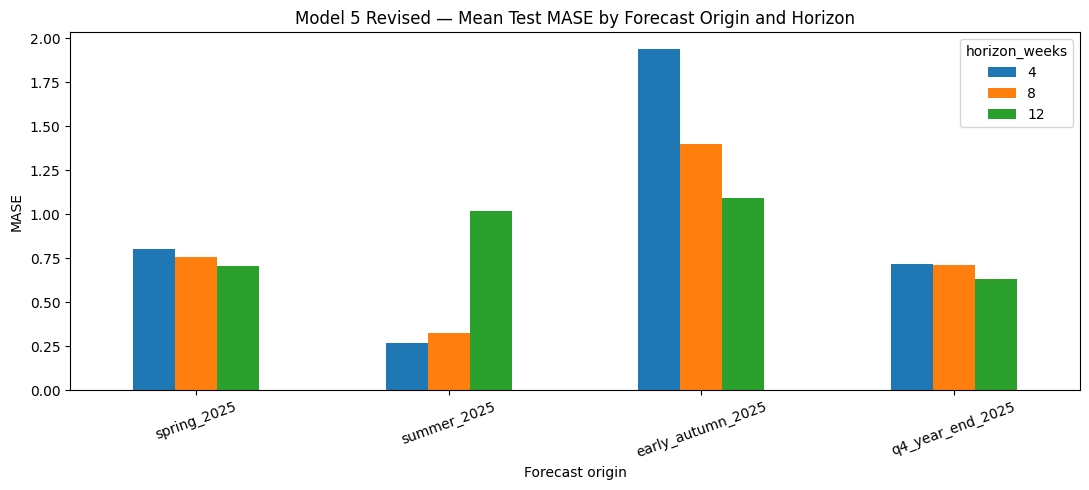

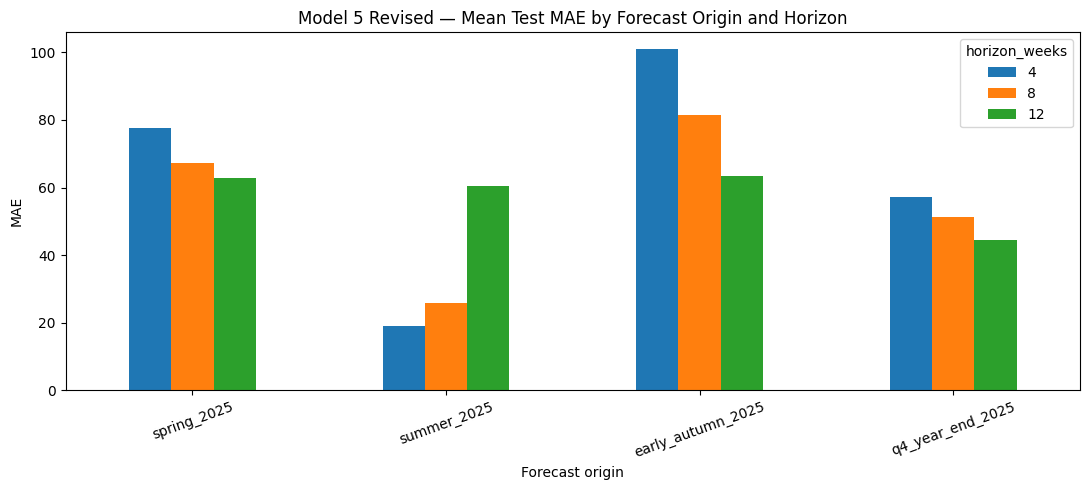

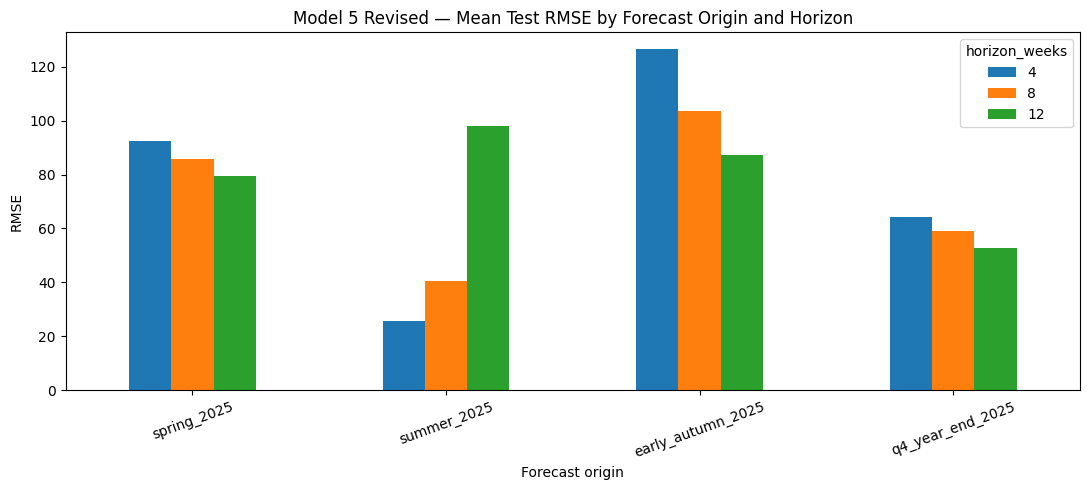

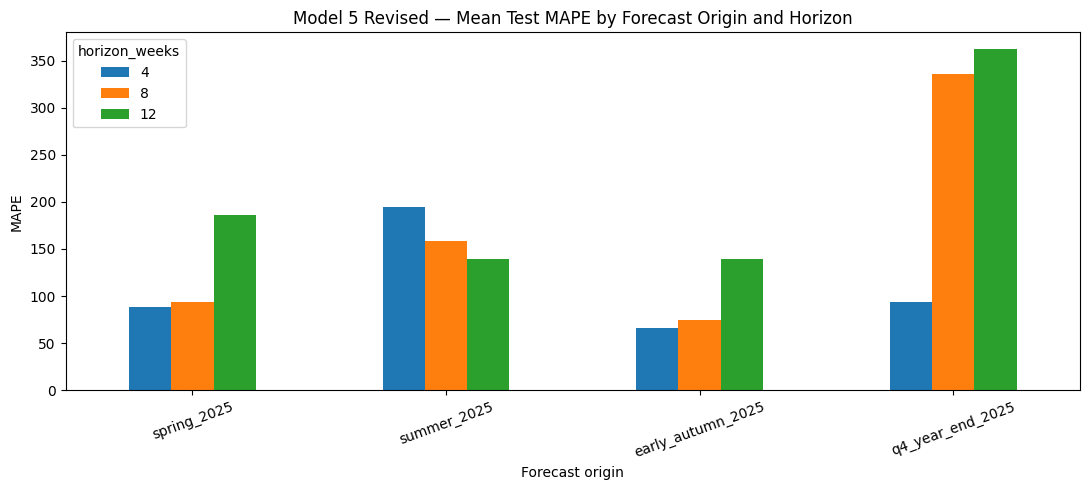

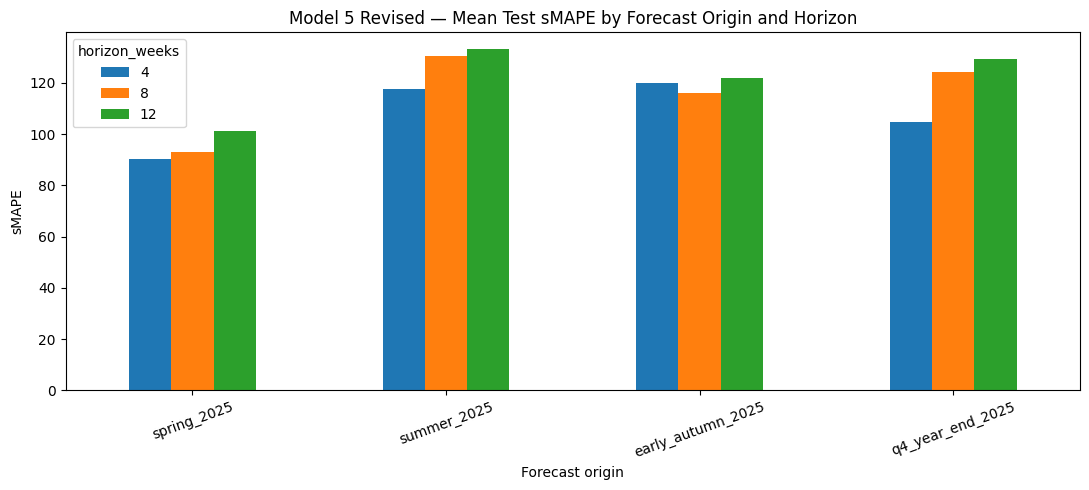

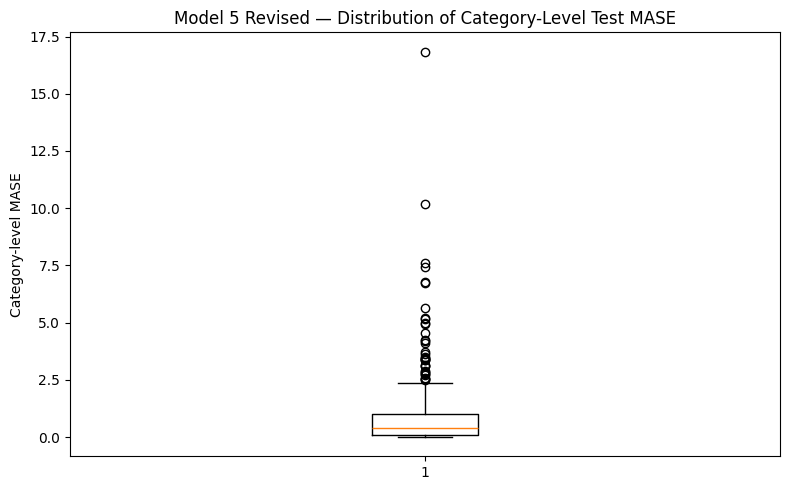

In [26]:
scenario_summary = (
    test_df.groupby(["scenario_id","outer_origin_label","horizon_weeks"], as_index=False)
    .agg(
        MAE=("MAE","mean"), RMSE=("RMSE","mean"), MAPE=("MAPE","mean"),
        sMAPE=("sMAPE","mean"), MASE=("MASE","mean"), median_MASE=("MASE","median"),
        valid_MASE_N=("MASE","count"),
        coverage_80=("coverage_80","mean"), coverage_95=("coverage_95","mean"),
        mean_width_80=("mean_width_80","mean"), mean_width_95=("mean_width_95","mean"),
    )
)

overall_summary = pd.DataFrame([{
    "mean_MAE": test_df.MAE.mean(),
    "mean_RMSE": test_df.RMSE.mean(),
    "mean_MAPE": test_df.MAPE.mean(),
    "mean_sMAPE": test_df.sMAPE.mean(),
    "mean_MASE": test_df.MASE.mean(),
    "median_MASE": test_df.MASE.median(),
    "mean_coverage_80": test_df.coverage_80.mean(),
    "mean_coverage_95": test_df.coverage_95.mean(),
    "mean_width_80": test_df.mean_width_80.mean(),
    "mean_width_95": test_df.mean_width_95.mean(),
    "valid_MASE_evaluations": int(test_df.MASE.notna().sum()),
    "undefined_MASE_evaluations": int(test_df.MASE.isna().sum()),
    "n_outer_evaluations": len(test_df),
}])

scenario_summary.to_csv(OUT_DIR / "model_5_scenario_summary.csv", index=False, encoding="utf-8-sig")
overall_summary.to_csv(OUT_DIR / "model_5_overall_summary.csv", index=False, encoding="utf-8-sig")

print("SCENARIO SUMMARY"); display(scenario_summary)
print("OVERALL SUMMARY"); display(overall_summary)

for metric in ["MASE","MAE","RMSE","MAPE","sMAPE"]:
    piv = scenario_summary.pivot(index="outer_origin_label", columns="horizon_weeks", values=metric).reindex(OUTER_ORIGINS.keys())
    ax = piv.plot(kind="bar", figsize=(11,5))
    ax.set_title(f"Model 5 Revised — Mean Test {metric} by Forecast Origin and Horizon")
    ax.set_xlabel("Forecast origin"); ax.set_ylabel(metric)
    plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(OUT_DIR / f"plot_test_{metric.lower()}_by_origin_horizon.png", dpi=160)
    plt.show()

plt.figure(figsize=(8,5))
plt.boxplot(test_df.MASE.dropna())
plt.ylabel("Category-level MASE")
plt.title("Model 5 Revised — Distribution of Category-Level Test MASE")
plt.tight_layout()
plt.savefig(OUT_DIR / "plot_category_mase_distribution.png", dpi=160)
plt.show()

,outer_origin_label,selected_strategy,count
0,early_autumn_2025,family_diverse_weighted,18
1,early_autumn_2025,single_best,8
2,early_autumn_2025,top3_equal,7
3,early_autumn_2025,top3_regularized_weighted,7
4,q4_year_end_2025,family_diverse_weighted,21
5,q4_year_end_2025,single_best,11
6,q4_year_end_2025,top3_equal,6
7,q4_year_end_2025,top3_regularized_weighted,2
8,spring_2025,family_diverse_weighted,21
9,spring_2025,single_best,12


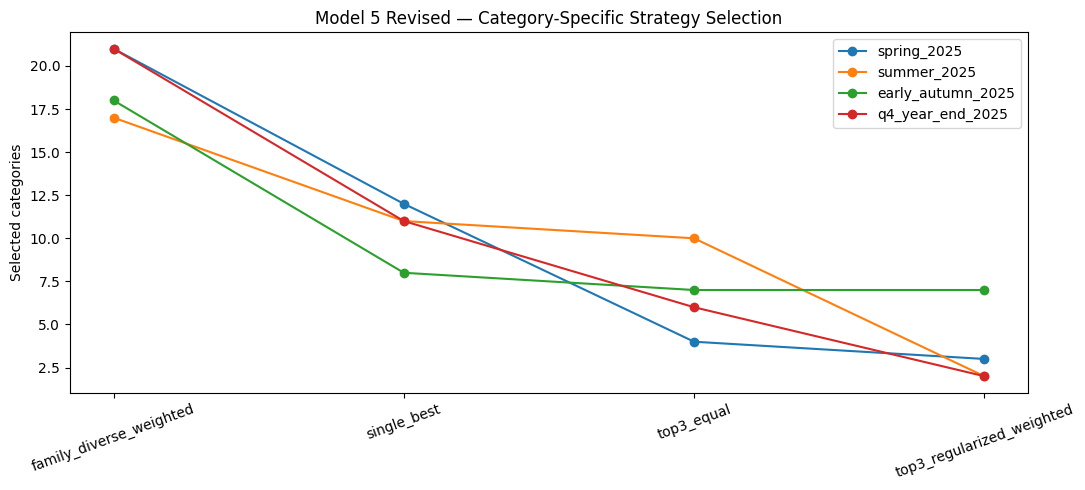

,outer_origin_label,horizon_weeks,category,MASE,MAE,MASE_scale,selected_strategy
249,early_autumn_2025,4,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,16.841518,36.393166,2.160920,family_diverse_weighted
250,early_autumn_2025,8,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,10.161242,21.957626,2.160920,family_diverse_weighted
251,early_autumn_2025,12,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,7.593082,16.408039,2.160920,family_diverse_weighted
131,summer_2025,12,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,7.450672,15.283429,2.051282,family_diverse_weighted
279,early_autumn_2025,4,ΚΑΣΚΟΛ ΑΝΔΡΙΚΟ,6.780892,409.737339,60.425287,family_diverse_weighted
297,early_autumn_2025,4,ΜΠΡΕΛΟΚ,6.724938,4.174099,0.620690,family_diverse_weighted
255,early_autumn_2025,4,ΓΟΥΝΑ,5.627839,41.206132,7.321839,single_best
256,early_autumn_2025,8,ΓΟΥΝΑ,5.197068,38.052093,7.321839,single_best
280,early_autumn_2025,8,ΚΑΣΚΟΛ ΑΝΔΡΙΚΟ,5.141661,310.686316,60.425287,family_diverse_weighted
330,early_autumn_2025,4,ΣΚΟΥΦΟΣ ΑΝΔΡΙΚΟΣ,4.969732,63.978159,12.873563,top3_regularized_weighted


In [27]:
strategy_counts = (
    selected_df.groupby(["outer_origin_label","selected_strategy"])
    .size().reset_index(name="count")
)
strategy_counts.to_csv(OUT_DIR / "model_5_strategy_selection_counts.csv", index=False, encoding="utf-8-sig")
display(strategy_counts)

plt.figure(figsize=(11,5))
for label in OUTER_ORIGINS:
    q = strategy_counts[strategy_counts.outer_origin_label == label]
    plt.plot(q.selected_strategy, q["count"], marker="o", label=label)
plt.ylabel("Selected categories")
plt.title("Model 5 Revised — Category-Specific Strategy Selection")
plt.xticks(rotation=20); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "plot_strategy_selection.png", dpi=160)
plt.show()

generalization = test_df[[
    "outer_origin_label","category","horizon_weeks","nested_cv_mean_MASE","MASE"
]].copy()
generalization["MASE_generalization_gap"] = generalization["MASE"] - generalization["nested_cv_mean_MASE"]
generalization.to_csv(OUT_DIR / "model_5_cv_vs_test_generalization.csv", index=False, encoding="utf-8-sig")

diag_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    for cat in categories:
        y = panel[(panel[CATEGORY_COL] == cat) & (panel[DATE_COL] < origin)].sort_values(DATE_COL)[TARGET_COL].values.astype(float)
        scale, status = mase_scale_info(y, SEASONAL_PERIOD)
        mean_y = float(np.mean(y)) if len(y) else np.nan
        std_y = float(np.std(y, ddof=1)) if len(y) > 1 else np.nan
        positive = y[y > 0]
        q95 = float(np.quantile(y, .95)) if len(y) else np.nan
        med = float(np.median(y)) if len(y) else np.nan
        diag_rows.append({
            "outer_origin_label": label, "category": cat,
            "history_n": len(y), "mean_demand": mean_y, "std_demand": std_y,
            "cv": std_y / mean_y if np.isfinite(mean_y) and mean_y > EPS else np.nan,
            "zero_rate": float(np.mean(y == 0)) if len(y) else np.nan,
            "positive_rate": float(np.mean(y > 0)) if len(y) else np.nan,
            "p95_demand": q95, "median_demand": med,
            "spike_ratio_p95_to_median": q95 / med if np.isfinite(med) and med > EPS else np.nan,
            "mase_scale": scale, "mase_scale_status": status,
            "positive_mean": float(np.mean(positive)) if len(positive) else np.nan,
        })

demand_diag = pd.DataFrame(diag_rows)
demand_diag.to_csv(OUT_DIR / "model_5_category_demand_diagnostics.csv", index=False, encoding="utf-8-sig")

tail_cases = test_df.sort_values("MASE", ascending=False).head(40)
tail_cases.to_csv(OUT_DIR / "model_5_worst_mase_cases.csv", index=False, encoding="utf-8-sig")
display(tail_cases[["outer_origin_label","horizon_weeks","category","MASE","MAE","MASE_scale","selected_strategy"]].head(20))

,scenario_id,coverage_80,coverage_95,mean_width_80,mean_width_95
0,early_autumn_2025_h12,0.733333,0.927083,53.417858,296.387588
1,early_autumn_2025_h4,0.631250,0.875000,46.897342,260.479324
2,early_autumn_2025_h8,0.668750,0.896875,46.054720,264.953374
3,q4_year_end_2025_h12,0.812500,0.956250,88.994739,325.114138
4,q4_year_end_2025_h4,0.743750,0.925000,59.421247,283.132389
5,q4_year_end_2025_h8,0.762500,0.937500,67.285370,286.851749
6,spring_2025_h12,0.797917,0.941667,98.223953,477.462811
7,spring_2025_h4,0.731250,0.862500,58.409641,332.835472
8,spring_2025_h8,0.781250,0.921875,86.208879,428.591392
9,summer_2025_h12,0.843750,0.945833,76.147465,337.219619


,forecast_step,coverage_80,coverage_95,mean_width_80,mean_width_95,n80,n95
0,1,0.77500,0.88125,58.835825,285.900204,160,160
1,2,0.76250,0.93125,56.621287,353.486303,160,160
2,3,0.72500,0.91875,55.063501,324.677770,160,160
3,4,0.79375,0.91875,63.119371,285.692101,160,160
4,5,0.77500,0.95625,74.210027,293.312701,160,160
5,6,0.80000,0.95000,66.951931,335.308859,160,160
6,7,0.81875,0.96875,80.097507,437.910739,160,160
7,8,0.82500,0.95000,92.056391,359.135901,160,160
8,9,0.84375,0.95625,105.793999,390.057594,160,160
9,10,0.83750,0.96250,108.010125,379.183353,160,160


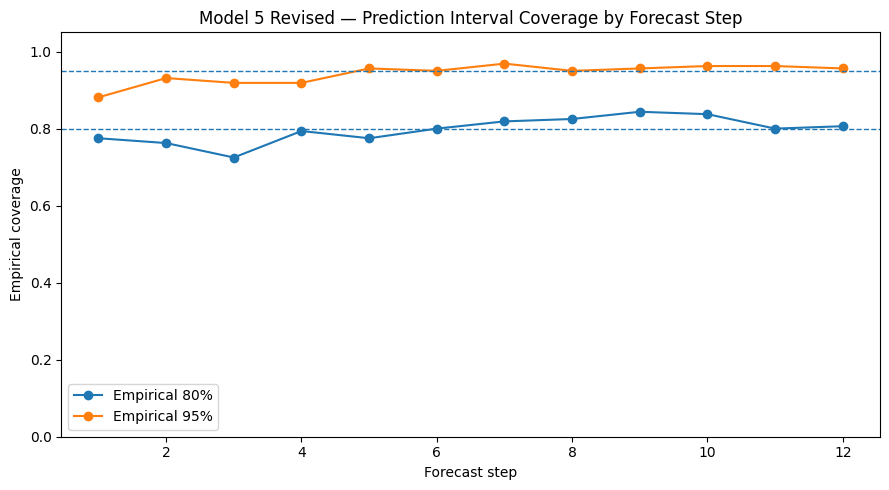

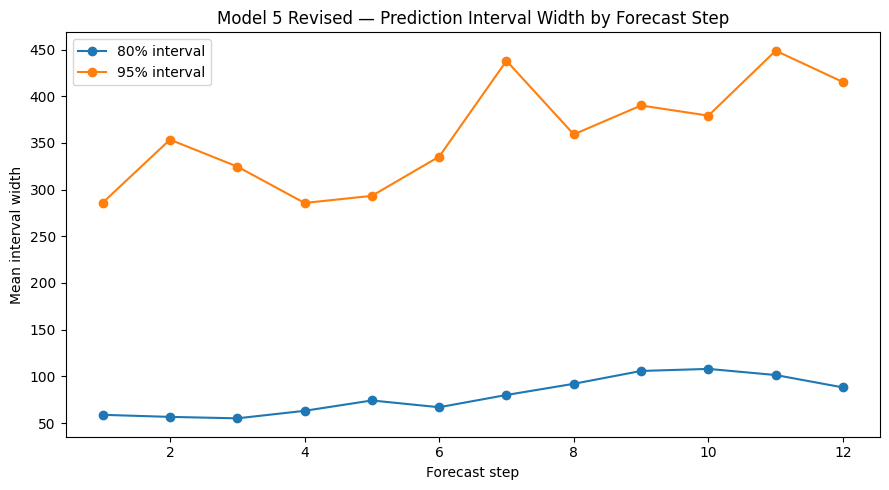

In [28]:
coverage_summary = scenario_summary[[
    "scenario_id","coverage_80","coverage_95","mean_width_80","mean_width_95"
]].copy()
coverage_summary.to_csv(
    OUT_DIR / "model_5_probabilistic_coverage_summary.csv",
    index=False, encoding="utf-8-sig"
)
display(coverage_summary)

step_rows = []
for step, g in forecasts_df.groupby("forecast_step"):
    valid80 = g.lower_80.notna() & g.upper_80.notna()
    valid95 = g.lower_95.notna() & g.upper_95.notna()
    step_rows.append({
        "forecast_step": step,
        "coverage_80": np.mean((g.loc[valid80,"y_true"] >= g.loc[valid80,"lower_80"]) &
                               (g.loc[valid80,"y_true"] <= g.loc[valid80,"upper_80"])) if valid80.any() else np.nan,
        "coverage_95": np.mean((g.loc[valid95,"y_true"] >= g.loc[valid95,"lower_95"]) &
                               (g.loc[valid95,"y_true"] <= g.loc[valid95,"upper_95"])) if valid95.any() else np.nan,
        "mean_width_80": np.mean(g.loc[valid80,"upper_80"] - g.loc[valid80,"lower_80"]) if valid80.any() else np.nan,
        "mean_width_95": np.mean(g.loc[valid95,"upper_95"] - g.loc[valid95,"lower_95"]) if valid95.any() else np.nan,
        "n80": int(valid80.sum()), "n95": int(valid95.sum()),
    })
step_coverage = pd.DataFrame(step_rows)
step_coverage.to_csv(OUT_DIR / "model_5_step_level_interval_diagnostics.csv", index=False, encoding="utf-8-sig")
display(step_coverage)

plt.figure(figsize=(9,5))
plt.plot(step_coverage.forecast_step, step_coverage.coverage_80, marker="o", label="Empirical 80%")
plt.plot(step_coverage.forecast_step, step_coverage.coverage_95, marker="o", label="Empirical 95%")
plt.axhline(.80, linestyle="--", linewidth=1)
plt.axhline(.95, linestyle="--", linewidth=1)
plt.ylim(0,1.05)
plt.xlabel("Forecast step"); plt.ylabel("Empirical coverage")
plt.title("Model 5 Revised — Prediction Interval Coverage by Forecast Step")
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "plot_interval_coverage_by_step.png", dpi=160)
plt.show()

plt.figure(figsize=(9,5))
plt.plot(step_coverage.forecast_step, step_coverage.mean_width_80, marker="o", label="80% interval")
plt.plot(step_coverage.forecast_step, step_coverage.mean_width_95, marker="o", label="95% interval")
plt.xlabel("Forecast step"); plt.ylabel("Mean interval width")
plt.title("Model 5 Revised — Prediction Interval Width by Forecast Step")
plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "plot_interval_width_by_step.png", dpi=160)
plt.show()

In [31]:
audit = []

for label, origin_s in OUTER_ORIGINS.items():

    origin = pd.Timestamp(origin_s)

    folds = inner_folds(origin)
    cal_blocks = calibration_blocks(origin)

    audit.append({

        "outer_origin_label": label,
        "all_inner_validation_ends_before_outer_origin":
            all(
                d[-1] < origin
                for _, _, d in folds
            ),
        "all_probabilistic_calibration_ends_before_outer_origin":
            all(
                d[-1] < origin
                for _, _, d in cal_blocks
            ),
        "outer_training_strictly_pre_origin":
            (
                panel[
                    panel[DATE_COL] < origin
                ][DATE_COL].max()
                < origin
            ),
        "all_exogenous_lags_at_least_max_horizon":
            (
                min(EXOG_LAGS) >= MAX_HORIZON
                if available_exog
                else True
            ),
    })

audit_df = pd.DataFrame(audit)

audit_df["expected_480_outer_evaluations"] = (
    len(test_df)
    ==
    len(categories)
    * len(OUTER_ORIGINS)
    * len(FORECAST_HORIZONS)
)

audit_df["expected_1920_weekly_forecasts"] = (
    len(forecasts_df)
    ==
    len(categories)
    * len(OUTER_ORIGINS)
    * MAX_HORIZON
)

audit_df["mase_uses_m52"] = (
    SEASONAL_PERIOD == 52
)
audit_df["outer_test_not_used_for_selection"] = True

audit_df["strategy_selection_is_leave_one_fold_out"] = True

audit_df["probabilistic_intervals_are_step_specific"] = (
    interval_quantiles_df[
        "forecast_step"
    ].nunique()
    ==
    MAX_HORIZON
)
audit_df["absolute_residual_calibration_used"] = (
    {"q80_abs", "q95_abs"}.issubset(
        interval_quantiles_df.columns
    )
)
audit_df["all_interval_quantiles_have_calibration_scores"] = bool(
    (
        interval_quantiles_df["n_scores"] > 0
    ).all()
)
audit_df["q95_not_narrower_than_q80"] = bool(
    (
        interval_quantiles_df[
            "q95_abs"
        ].fillna(np.inf)
        >=
        interval_quantiles_df[
            "q80_abs"
        ].fillna(-np.inf)
    ).all()
)
audit_df["outer_95_intervals_contain_80_intervals"] = bool(

    (
        forecasts_df[
            "lower_95"
        ].fillna(np.inf)
        <=
        forecasts_df[
            "lower_80"
        ].fillna(np.inf)
    ).all()

    and

    (
        forecasts_df[
            "upper_95"
        ].fillna(-np.inf)
        >=
        forecasts_df[
            "upper_80"
        ].fillna(-np.inf)
    ).all()
)

audit_df["all_interval_widths_nonnegative"] = bool(

    (
        forecasts_df["upper_80"]
        -
        forecasts_df["lower_80"]
        >= 0
    ).all()

    and

    (
        forecasts_df["upper_95"]
        -
        forecasts_df["lower_95"]
        >= 0
    ).all()
)

audit_df["all_point_forecasts_nonnegative"] = bool(
    (
        forecasts_df[
            "y_pred"
        ] >= 0
    ).all()
)

audit_df["all_forecast_steps_valid"] = bool(
    forecasts_df[
        "forecast_step"
    ].between(
        1,
        MAX_HORIZON
    ).all()
)

audit_df.to_csv(
    OUT_DIR /
    "model_5_integrity_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

display(audit_df)

all_audit_true = bool(
    audit_df
    .select_dtypes(include="bool")
    .all()
    .all()
)

print(
    "\nALL AUDIT CHECKS TRUE:",
    all_audit_true
)

if not all_audit_true:

    failed_checks = [
        col
        for col in audit_df.select_dtypes(
            include="bool"
        ).columns
        if not audit_df[col].all()
    ]

    print(
        "FAILED CHECKS:",
        failed_checks
    )

log = {

    "model":
        (
            "Model 5 Revised - "
            "Category-Specific Expert Ensemble "
            "with Probabilistic Forecasts"
        ),
    "outer_origins":
        OUTER_ORIGINS,

    "horizons":
        FORECAST_HORIZONS,
    "inner_cv_horizon":
        INNER_CV_HORIZON,

    "inner_offsets_weeks":
        INNER_CV_OFFSETS_WEEKS,

    "strategy_selection":
        (
            "Leave-one-inner-fold-out strategy evaluation. "
            "Strategy type is selected exclusively from "
            "pre-origin inner validation folds; final ensemble "
            "members and weights are estimated from all three "
            "pre-origin inner folds."
        ),
    "seasonal_mase_period":
        SEASONAL_PERIOD,

    "mase_denominator":
        (
            "Mean absolute seasonal-naive error with m=52, "
            "computed exclusively from observations available "
            "before the corresponding forecast origin."
        ),
    "expert_candidates":
        [
            x["id"]
            for x in EXPERTS
        ],

    "strategies": [
        "single_best",
        "top3_equal",
        "top3_regularized_weighted",
        "family_diverse_weighted",
    ],
    "probabilistic_intervals":
        (
            "Step-specific empirical conformal-style prediction "
            "intervals calibrated from pooled absolute forecast "
            "residuals generated on historical calibration blocks "
            "strictly before each outer forecast origin. "
            "Residuals are pooled across categories separately "
            "for each outer origin and forecast step. "
            "Finite-sample empirical quantiles are calculated "
            "separately for the 80% and 95% interval levels. "
            "No MASE-scale normalization is used in the final "
            "interval construction."
        ),

    "probabilistic_calibration_score":
        "absolute forecast residual",

    "probabilistic_pooling":
        (
            "Across categories within the same outer origin "
            "and forecast step."
        ),

    "probabilistic_quantiles":
        "finite-sample empirical quantiles",

    "calibration_offsets_weeks":
        CALIBRATION_OFFSETS_WEEKS,

    "calibration_horizon":
        CALIBRATION_HORIZON,

    "interval_levels":
        INTERVAL_LEVELS,
    "exogenous_variables":
        available_exog,

    "exogenous_lags":
        EXOG_LAGS,

    "exogenous_availability_rule":
        (
            "Operational exogenous variables are included only "
            "through lags greater than or equal to the maximum "
            "forecast horizon, ensuring that all values are "
            "available at the forecast origin."
        ),
    "leakage_control":
        (
            "All model selection, ensemble construction, "
            "probabilistic calibration and feature construction "
            "use information available strictly before the "
            "corresponding forecast origin. Outer-test actuals "
            "are used exclusively for final evaluation."
        ),
}
with open(
    OUT_DIR /
    "model_5_experiment_log.json",
    "w"
) as f:

    json.dump(
        log,
        f,
        indent=2,
        default=str
    )


print(
    "\nExperiment log saved."
)

print(
    "All outputs saved to:",
    OUT_DIR
)

,outer_origin_label,all_inner_validation_ends_before_outer_origin,all_probabilistic_calibration_ends_before_outer_origin,outer_training_strictly_pre_origin,all_exogenous_lags_at_least_max_horizon,expected_480_outer_evaluations,expected_1920_weekly_forecasts,mase_uses_m52,outer_test_not_used_for_selection,strategy_selection_is_leave_one_fold_out,probabilistic_intervals_are_step_specific,absolute_residual_calibration_used,all_interval_quantiles_have_calibration_scores,q95_not_narrower_than_q80,outer_95_intervals_contain_80_intervals,all_interval_widths_nonnegative,all_point_forecasts_nonnegative,all_forecast_steps_valid
0,spring_2025,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
1,summer_2025,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
2,early_autumn_2025,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
3,q4_year_end_2025,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True



ALL AUDIT CHECKS TRUE: True

Experiment log saved.
All outputs saved to: /content/drive/MyDrive/model_5_category_specific_ensemble_revised_outputs
